# Why are callers waiting longer — and what should Care do?

## The main finding: more calls, longer conversations, and unfinished recovery
**Northstar Home · fictional case · read as of October 2, 2026.** Records cover April–September 2026.

September brought more calls and more time spent on each answered call. A recurring Wi-Fi issue is an important part of the picture. For customers whose hub qualified for help, the approved response required **two actions: a replacement hub and a free year of Plus**. Many sampled General Care calls did not complete both.

**Recommended next step:** give Guides a short, practical recovery guide and practice with realistic cases. Make the right help article easier to find, and make sure unfinished account credits receive follow-up. Test this approach with small groups before a wider launch.

### How to read this notebook
Read the summary cards, charts, and “What this means” notes first. You do not need to understand Python. Results are already displayed; code can remain collapsed. “Guide” means customer-care representative. “Recovery” means the approved help for an eligible Wi-Fi hub.

1. **What changed?** August compared with September.
2. **Where does recovery break down?** A closer look at sampled calls.
3. **What should change?** A practical recommendation and small test.
4. **How trustworthy are the figures?** Sources and data checks in the appendix.

**Reading the evidence:** daily operating figures include all recorded calls in each queue. Individual-call analysis covers a smaller sample. Quality reviews and customer feedback were selected unevenly. These sources help identify patterns; they do not prove what caused the changes.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'analysis_utils.py').exists() else Path.cwd() / 'northstar_analysis'
assert (ROOT / 'analysis_utils.py').exists(), 'Run from northstar_analysis or its parent.'
sys.path.insert(0, str(ROOT))
from analysis_utils import *
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
D = load_data()
calls, ops = D['calls'], D['ops']

from presentation import table, cards, comparison, PercentFormatter, StrMethodFormatter

In [2]:
ops['Month'] = ops.Date.dt.to_period('M').astype(str)
monthly = ops.groupby(['Queue','Month']).apply(population_metrics, include_groups=False)
a, b = monthly.loc[('General Care','2026-08')], monthly.loc[('General Care','2026-09')]
post = calls[calls.Queue.eq('General Care') & calls['Recovery available'] & calls['Eligible for recovery'].eq('Yes')]
complete = int(post['Complete recovery'].sum())
cards([
 ('Calls arriving each day', f"{a.offered_per_day:,.0f} → {b.offered_per_day:,.0f}", 'General Care: August → September'),
 ('Time handling an answered call', f"{a.AHT_min:.1f} → {b.AHT_min:.1f} minutes", 'Includes talking, hold time, and after-call notes'),
 ('Callers hanging up before help', f"{a.abandonment:.1%} → {b.abandonment:.1%}", 'Of all calls arriving in General Care'),
 ('Both recovery steps completed', f"{complete} of {len(post)} sampled calls", 'Eligible General Care calls, September 21–30 only')])

### The decision these findings support
Treat this as a recovery-workflow and capacity problem. Coaching should help Guides move from listening to the right action, while Operations fixes search and transaction obstacles.

**Important limit:** 76 of 204 describes the eligible calls in this sample. It does not mean that only 37% of all customers received help. We also cannot tell whether a later contact completed an unfinished recovery.

In [3]:
ops['Month'] = ops.Date.dt.to_period('M').astype(str)
monthly = ops.groupby(['Queue','Month']).apply(population_metrics, include_groups=False)
monthly.to_csv(OUT/'monthly_population_metrics.csv')
gc = monthly.loc['General Care']
a, b = gc.loc['2026-08'], gc.loc['2026-09']
table(comparison(a,b).rename(columns={'Earlier period':'August 2026','Later period':'September 2026'}),
      '1. General Care was under more pressure in September',
      'All recorded daily operations. A percentage point is the difference between two percentages: 4% to 28% is a rise of 24 points.')

What we measured,August 2026,September 2026,Change
Calls arriving each day,"22,100","27,098","+4,999 calls/day"
Average time spent handling an answered call,8.58 minutes,11.14 minutes,+2.56 minutes
Callers who hung up before reaching a Guide,4.2%,28.5%,+24.3 percentage points
Answered calls tagged WN7 or WNM-7,1.3%,30.3%,+29.0 percentage points
Staff present compared with planned staffing,94.1%,92.0%,-2.1 percentage points


### What this means: callers face pressure at both ends
More people called in September, and each answered call took longer. About **28 in every 100 arriving callers hung up before reaching help**, compared with about **4 in every 100** in August.

Calls tagged with the WN7 hub or its WNM-7 bundle also became more common. At the same time, the share of planned staff actually present fell slightly, from about 94% to 92%.

**What to do with this finding:** address call handling and coverage together. The records do not tell us how much of the overall rise in call time was caused by the Wi-Fi issue. A product tag is not proof of a defective or eligible hub.

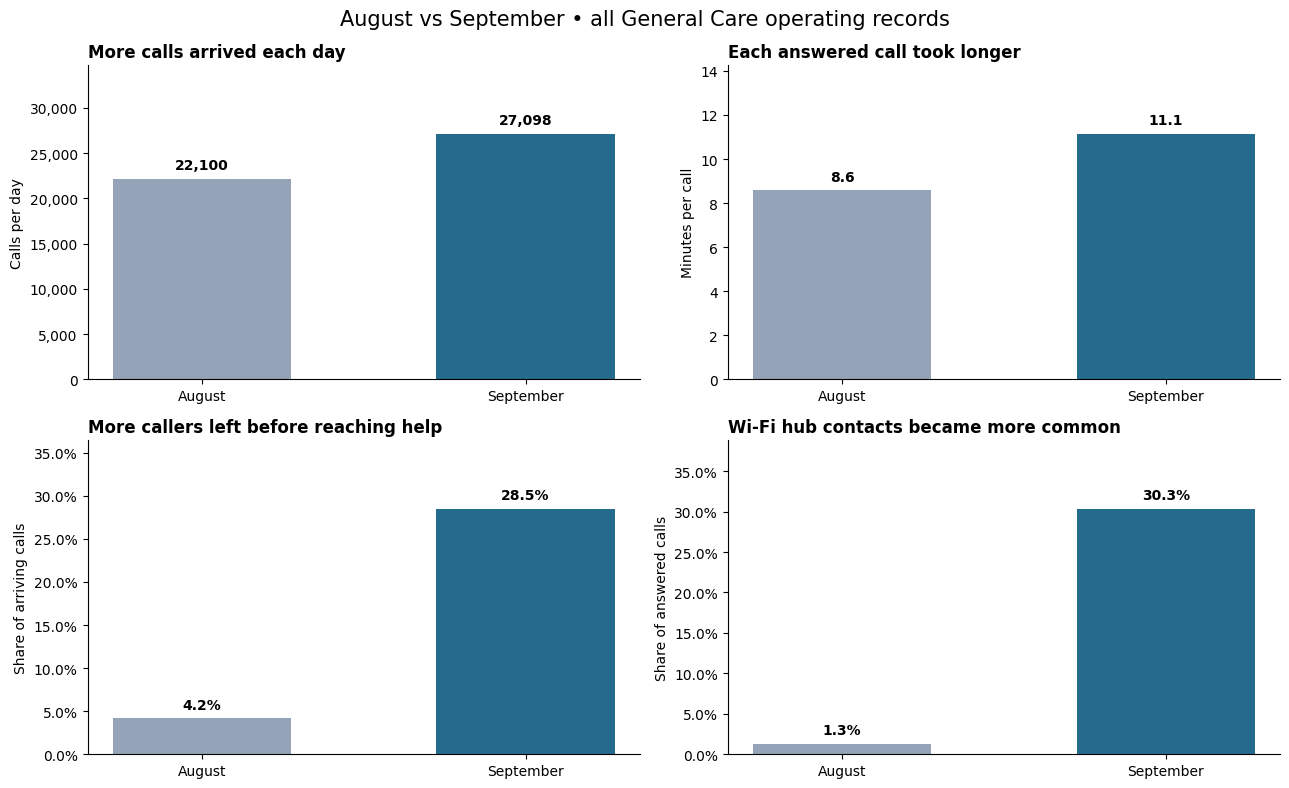

In [4]:
g = ops[ops.Queue.eq('General Care')].sort_values('Date')
fig, axes = plt.subplots(2,2,figsize=(13,8))
metrics = [('offered_per_day','More calls arrived each day','Calls per day',False),
 ('AHT_min','Each answered call took longer','Minutes per call',False),
 ('abandonment','More callers left before reaching help','Share of arriving calls',True),
 ('WN7_contact_share','Wi-Fi hub contacts became more common','Share of answered calls',True)]
for ax,(key,title,unit,percent) in zip(axes.flat,metrics):
 values=[a[key],b[key]]
 ax.bar(['August','September'],values,color=['#94a3b8','#246b8e'],width=.55)
 ax.set_title(title,loc='left',fontweight='bold');ax.set_ylabel(unit);ax.set_ylim(0,max(values)*1.28)
 for i,v in enumerate(values):
  ax.text(i,v+max(values)*.04,f'{v:.1%}' if percent else f'{v:,.1f}' if key=='AHT_min' else f'{v:,.0f}',ha='center',fontweight='bold')
 if percent: ax.yaxis.set_major_formatter(PercentFormatter(1))
 else: ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
fig.suptitle('August vs September • all General Care operating records',fontsize=15)
fig.tight_layout();plt.show()

In [5]:
calls['Month'] = calls['Call date'].dt.to_period('M').astype(str)
segments = calls.groupby(['Queue','Month','Product segment'])['AHT minutes'].agg(n='size',mean='mean',median='median')
segment_view=segments.loc[('General Care',['2026-08','2026-09']),:].reset_index()
segment_view['Month']=segment_view['Month'].map({'2026-08':'August','2026-09':'September'})
segment_view['Average minutes']=segment_view['mean'].map('{:.1f}'.format)
table(segment_view[['Month','Product segment','n','Average minutes']].rename(columns={'Product segment':'Product group','n':'Calls in sample'}),
 'A closer look: call length by product group',
 'Sampled General Care calls only. Unknown means the product code was missing. WN7-containing includes the WNM-7 bundle; a product tag does not establish eligibility.')
components = ops.groupby(['Queue','Month']).apply(
 lambda x: pd.Series({k:np.average(x[k],weights=x['Answered contacts']) for k in
 ['Average talk minutes','Average hold minutes','Average wrap minutes']}),include_groups=False)
comp=components.loc[('General Care',['2026-08','2026-09']),:].reset_index().drop(columns='Queue')
comp.columns=['Month','Talking (minutes)','On hold (minutes)','After-call notes (minutes)']
comp['Month']=comp.Month.map({'2026-08':'August','2026-09':'September'})
for col in comp.columns[1:]:comp[col]=comp[col].map('{:.1f}'.format)
table(comp,'Where did handling time go?', 'All General Care answered calls; averages reflect the number of calls handled each day.')

Month,Product group,Calls in sample,Average minutes
August,Other products,3139,8.5
August,Unknown,28,8.6
August,WN7-containing,49,11.7
September,Other products,2054,8.5
September,Unknown,15,10.8
September,WN7-containing,882,17.2


Month,Talking (minutes),On hold (minutes),After-call notes (minutes)
August,6.1,1.4,1.1
September,7.9,1.8,1.5


## 2. Why having an article was not enough
The approved offer became available to different teams at different times:

| Date | What became possible |
|---|---|
| August 31 | Product confirmed the Wi-Fi issue. |
| September 10 | The replacement plus free-year offer was approved. |
| September 12 | Specialist Care began a small trial. |
| September 21 | General Care gained access to the help article. |

The article went into a weekly update, but there was no separate incident alert or scheduled briefing across shifts. We do not know who read it. Meeting notes also describe Guides finding an older restart article or being unsure what to do when a Plus credit stayed pending.

**What this means:** putting guidance online is a start. Guides also need to find it, recognize when to use it, and finish both recovery actions. The next chart looks only at eligible General Care calls **after** its article became available; earlier calls are not judged against a process they could not yet use.

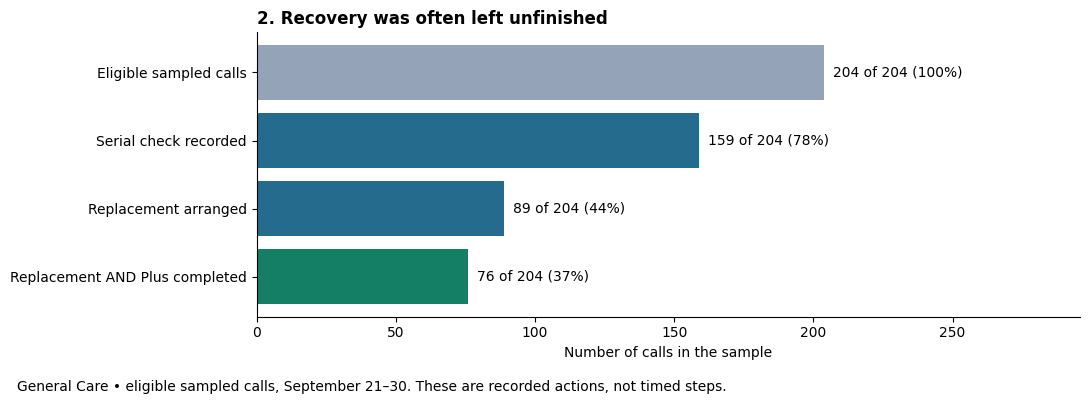

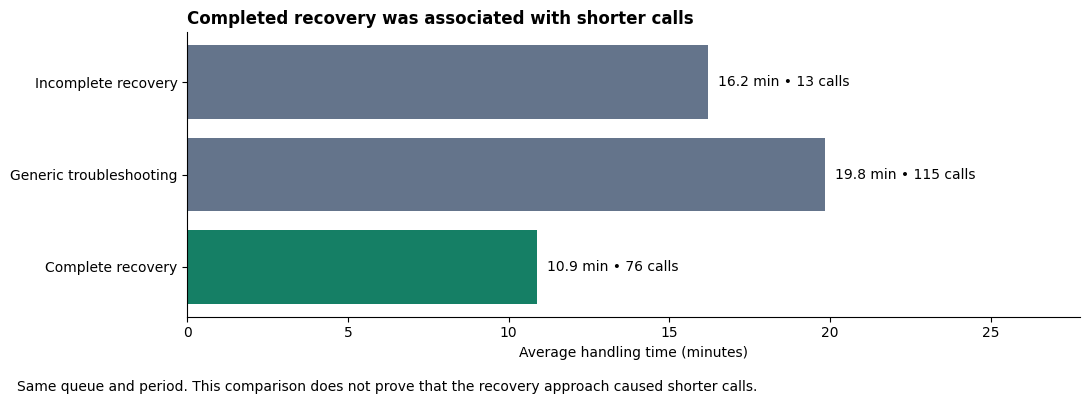

In [6]:
phase = calls.groupby(['Queue','Phase']).apply(recovery_metrics,include_groups=False)
available = calls[calls['Recovery available']].copy()
recovery = available.groupby('Queue').apply(recovery_metrics,include_groups=False)
recovery.to_csv(OUT/'available_period_recovery.csv')
e = available[available['Eligible for recovery'].eq('Yes')]
path = e.groupby(['Queue','Conversation path'])['AHT minutes'].agg(n='size',mean='mean',median='median')
gc_eligible=e[e.Queue.eq('General Care')]
counts=[len(gc_eligible),int(gc_eligible['Serial verified'].eq('Yes').sum()),
        int(gc_eligible['Replacement arranged'].eq('Yes').sum()),int(gc_eligible['Complete recovery'].sum())]
fig,ax=plt.subplots(figsize=(11,4))
labels=['Eligible sampled calls','Serial check recorded','Replacement arranged','Replacement AND Plus completed']
ax.barh(labels[::-1],counts[::-1],color=['#157f65','#246b8e','#246b8e','#94a3b8'])
for i,v in enumerate(counts[::-1]):ax.text(v+3,i,f'{v} of {counts[0]} ({v/counts[0]:.0%})',va='center')
ax.set_xlim(0,counts[0]*1.45);ax.set_xlabel('Number of calls in the sample')
ax.set_title('2. Recovery was often left unfinished',loc='left',fontweight='bold')
fig.text(.02,.01,'General Care • eligible sampled calls, September 21–30. These are recorded actions, not timed steps.',fontsize=10)
fig.tight_layout(rect=[0,.05,1,1]);plt.show()
subset=path.loc['General Care'].reset_index()
fig,ax=plt.subplots(figsize=(11,4))
ax.barh(subset['Conversation path'],subset['mean'],color=['#157f65' if s=='Complete recovery' else '#64748b' for s in subset['Conversation path']])
for i,row in subset.iterrows():ax.text(row['mean']+.3,i,f"{row['mean']:.1f} min • {int(row['n'])} calls",va='center')
ax.set_xlim(0,subset['mean'].max()*1.4);ax.set_xlabel('Average handling time (minutes)')
ax.set_title('Completed recovery was associated with shorter calls',loc='left',fontweight='bold')
fig.text(.02,.01,'Same queue and period. This comparison does not prove that the recovery approach caused shorter calls.',fontsize=10)
fig.tight_layout(rect=[0,.05,1,1]);plt.show()

### What the recovery charts tell us
Of **204 eligible General Care calls examined from September 21–30**:

- **76 completed both actions**: a replacement and Plus.
- **13 arranged a replacement but did not record Plus as attached.**
- **115 followed generic troubleshooting** rather than completing the approved offer.

The records also show a serial check on 159 of those 204 calls. The horizontal bars show recorded actions, not the exact order or timing of steps.

**Complete recovery was associated with shorter calls:** about **10.9 minutes across 76 calls**, compared with **19.8 minutes across 115 generic-troubleshooting calls**. This suggests a useful approach to test, but does not prove it makes calls shorter. Easier cases, different Guides, or other factors could explain part of the difference.

Specialist Care completed both steps on 163 of 193 eligible sampled calls after its September 12 start. Those customers and dates differ, so that figure is useful background rather than a fair ranking of the teams.

**What to do with this finding:** coach complete recovery, not speed alone. The data cannot show whether an unfinished call was resolved later.

In [7]:
q = D['qa_joined']; f = D['feedback_joined']
qpost=q[q['Recovery available'] & q['Eligible for recovery'].eq('Yes')]
fpost=f[f['Recovery available'] & f['Eligible for recovery'].eq('Yes')]
feedback_view=fpost[fpost.Queue.eq('General Care')].groupby('Conversation path').agg(
 responses=('Feedback ID','size'),average=('Satisfaction score','mean')).reset_index()
feedback_view['Average rating (out of 5)']=feedback_view.average.map('{:.1f}'.format)
table(feedback_view[['Conversation path','responses','Average rating (out of 5)']].rename(
 columns={'Conversation path':'What happened on the call','responses':'People who responded'}),
 'What customers who responded told us',
 'Eligible General Care calls after September 21. Responses are voluntary and unevenly selected; these ratings do not represent every customer.')
qa_view=qpost.groupby('Queue').agg(reviewed=('QA review ID','size'),recap=('Recap complete',lambda x:x.eq('Yes').sum())).reset_index()
qa_view['Clear recap recorded']=qa_view.apply(lambda row:f"{row.recap} of {row.reviewed} reviewed calls",axis=1)
table(qa_view[['Queue','Clear recap recorded']],'Did reviewed calls explain what happens next?',
 'Selected quality reviews after each queue gained the recovery path. Different selection and dates mean the queues are not a fair head-to-head comparison.')

What happened on the call,People who responded,Average rating (out of 5)
Complete recovery,47,4.5
Generic troubleshooting,61,1.5
Incomplete recovery,4,2.0


Queue,Clear recap recorded
General Care,47 of 75 reviewed calls
Specialist Care,62 of 79 reviewed calls


### Customers who responded described a better experience after complete recovery
Among eligible General Care respondents, those with both recovery steps complete rated the experience **4.5 out of 5 on average (47 responses)**. Those who went through generic troubleshooting averaged **1.5 out of 5 (61 responses)**.

**Treat this as a clue, not a company-wide satisfaction score.** Customers chose whether to respond, and the feedback collection placed extra attention on WN7. Quality reviewers also deliberately selected higher-risk and longer calls. Their findings help identify what to coach; they do not tell us how often every Guide makes a mistake.

## 3. What to put in Guides’ hands next week
**The practical learning response:** a ≤5-minute worked example can introduce the pivot from acknowledgment to action, but must link to the current Beacon article. Pair it with branch practice and one observed-call coaching check. Do not teach every Guide every product, force a memorized speech, or reward shorter calls at the expense of recovery.

**One-screen cue — learner-facing draft, subject to Product/Quality review:**
1. **Hear the disruption.** “Losing the whole connection during work calls is disruptive. You said it drops briefly and returns by itself. I can check whether your hub is included in the group we can replace.” Confirm the reported pattern; then model and hub serial. WNM-7 contains a WN7 hub.
2. **Check Orbit, don't guess.** Use BH-4419 / PO-117 and the serial eligibility result. Model alone is not eligibility. If not eligible, continue appropriate troubleshooting/escalation. If serial unavailable or tool down, open eligibility review and give a specific follow-up expectation you can keep; do not invent timing.
3. **Eligible: do both actions.** “Your hub is eligible for a no-cost replacement. We'll also attach twelve months of Plus at no cost as a goodwill benefit. Plus is not a repair for this issue and doesn't prevent every outage.” Verify replacement confirmation and Plus **Applied**. Keep satellite nodes unless separately diagnosed. Do not require repeated restarts before the approved remedy.
4. **Close the loop accurately.** Recap confirmation, shipping estimate shown in Orbit (normally five–seven business days), Plus status, and next steps. Document confirmation/status/follow-up. “The replacement is confirmed; the Plus credit is still pending. Your recovery case remains open, and [specific owner/follow-up expectation confirmed in the tool].” Bracketed text must be filled with a real commitment, never read as a promise without verification. Use unresolved recovery follow-up when either transaction fails; do not report full completion.

**Practice prompts and answer check:**
- Eligible customer has already restarted three times: acknowledge work interruption, check serial once, explain both benefits, verify both transactions, recap; no new restart condition.
- WN7 serial is not eligible: no replacement/free-year promise; diagnose/escalate the actual issue.
- Order confirmed, credit pending: do not call recovery complete; keep case open, record both statuses and arrange specific follow-up.
- Serial absent or eligibility tool unavailable: eligibility review and clear follow-up, no guessed entitlement.

Team Lead checks the observable branch and transaction status, gives one specific correction, and has the Guide retry. Attendance and quiz completion track reach, not transfer to the call.

## 4. A small test before a wider rollout — proposed, not yet implemented
| Owner | Next step | Evidence before expansion |
|---|---|---|
| Dana / Priya | Sponsor 24-General-Care-Guide pilot across shifts and tenure groups; match comparison shifts or randomize small cohorts if practical | Roster, exposure dates, comparable call mix, baseline reviews |
| Learning + Mateo | ≤5-minute model, one-screen cue, 7-minute branch practice | 12 minutes/Guide; 24 × 12 = **4.8 Guide-hours** total, excluding Lead/QA effort |
| Renee / WFM | Stagger six groups of four outside 11 a.m.–4 p.m. Central, subject to coverage approval | 48 Guide-minutes removed per cohort; model actual queue effect rather than infer from daily averages |
| Product Operations / Knowledge / Systems | Validate offer language; fix customer-language search and older-article cross-link; confirm screen access and unresolved follow-up | Successful retrieval and transaction walkthrough from General Care workstation; no assumed sandbox |
| Priya / Team Leads + Elias / Quality | One coached call per participating Guide within a week; focused reviews across both groups, including ineligible and failed-transaction cases | Recognition, serial result followed, two transactions or honest unresolved handoff, clear recap; no new punitive score |
| Jules + Product/Legal | Own proactive notice timing and audience | Notice remains in review as of October 1; annotate actual release if it occurs |

### How to test the recommendation fairly
Run the proposed test for two weeks with small groups at different times. First collect a week of results while the article is already available. Compare with similar General Care teams handling calls during the test. If practical, assign the groups by chance. Otherwise explain differences in shifts, Guide experience, call types, and staffing. Record any search or system changes happening at the same time: improved results would not tell us which change helped most.

### What would justify a wider rollout?
These starting rules need agreement from the owners; they are not proven targets.

- Guides choose the safe next step in every practice case, including cases that do not qualify.
- Reviewed ineligible calls contain no unsupported offer.
- Completion of both steps improves by at least **15 percentage points** compared with a similar starting period. For example, 40% to 55% is a 15-point increase. Examine at least **30 eligible calls in each group**; even then, consider how calls were selected before drawing a conclusion.
- In comparable operating windows, the share hanging up before help does not worsen by more than **2 percentage points**, and estimated wait does not worsen by more than **half a minute**.

If too few calls were reviewed, the answer is “we do not know yet.” Separate system failures from missed Guide actions.

If completion improves but queues worsen, revise capacity/cohort scheduling before expansion. If serial checking improves but Plus failures persist, prioritize Systems follow-up rather than repeat empathy training. Specialist capacity is limited (about 70 extra contacts/day temporarily per September 19 notes); blanket transfers and an automated offer lack approval and are not recommended as an immediate substitute.

### What we still cannot tell from these files
 We cannot identify repeat calls from the same household, check whether an order shipped or a credit was later applied, or see which Guides took part in training. Daily totals also hide busy periods within a shift. Those extra records are needed before claiming fewer repeat calls, a successful rollout, or enough ongoing capacity. The monitoring call list is a starting point for review, not a count of all households still waiting.

## Source traceability
- `DATA_DICTIONARY.md`: populations, duplicates, bias, retrospective eligibility, chronology.
- `Orbit_operations.xlsx`: Daily operations and Staffing for population metrics; Call sample for paths and duration; Product catalog for code checks.
- `Quality_and_feedback.xlsx`: selected reviews and voluntary responses; joined on Call ID with cardinality checks.
- `Case_info.md`: BH-2240 vs BH-4419, PO-117 approved recovery, CLEAR, product limits.
- `threads.md`, “Guide reference follow-up,” September 28: distribution versus readership.
- `meetings.md`: August 31 confirmation; September 10 approval; September 16 calibration; September 18 Guide feedback; September 19 workforce; September 21 release; September 24 open items; October 1 leadership discussion.
- Dana's September 29 email frames urgency and original short-video request. `00_START_HERE.md` establishes fictional scope and case date. `INTERVIEW_PREP_PROMPT.md` adds no empirical case facts.

## Appendix: what the data includes and how it was checked
Daily operations and staffing are **full populations**; sampled calls are not demand. QA oversamples long/recovery-risk calls; feedback is voluntary and oversamples WN7 outreach. Neither produces population behavior or satisfaction rates.

The loader detects Excel headers below four title/note rows, trims strings, parses dates, converts metrics, validates keys and joins, and removes only consistent duplicate Call IDs. Missing product/reason values remain missing; no inferred eligibility or imputation. WN7 + WNM-7 product buckets identify WN7-containing contacts, not affected households or eligible serials. Source eligibility is retrospective: pre-release non-recovery is not a Guide failure.

AHT and its components are independently rounded to one decimal; a 0.15-minute tolerance accommodates the observed ±0.1-minute differences without rewriting source durations. Daily wait lacks a denominator definition: offered-weighted wait is explicitly a proxy. Occupancy is scheduled-hours weighted, also a proxy. AHT is answered-contact weighted; abandonment is total abandoned / total offered.


In [8]:
table(D['audit'].rename(columns={'table':'Source table','raw_rows':'Rows received','header_excel_row':'Header row in Excel','missing_key':'Rows missing an identifier','clean_rows':'Rows kept','removed_rows':'Duplicate rows removed'}), 'Data checks: what was kept and removed')
missing = calls[['Product code','Reason code']].isna().sum()
table(pd.DataFrame({'Missing information':['Product code','Reason code'],'Calls affected':missing.values,
 'Share of sampled calls':[f'{v/len(calls):.1%}' for v in missing.values]}),'What information was missing?',
 'Missing values were left blank; they were not guessed.')
table(D['catalog_unmatched'].rename(columns={'Product code':'Code absent from catalog','sample_calls':'Calls retained in sample'}),
 'Product codes needing a catalog update', 'These calls remain in the analysis. No product descriptions were invented.')
export_clean({**D, 'calls':calls.drop(columns='Month',errors='ignore')})

Source table,Rows received,Header row in Excel,Rows missing an identifier,Rows kept,Duplicate rows removed
daily,366,5,0,366,0
calls,20028,5,0,20000,28
staff,366,5,0,366,0
catalog,250,5,0,250,0
qa,1600,5,0,1600,0
feedback,2200,5,0,2200,0


Missing information,Calls affected,Share of sampled calls
Product code,158,0.8%
Reason code,260,1.3%


Code absent from catalog,Calls retained in sample
LC-63,80
SP-14,77
CM-32,76
LC-41,73
WNM-9,73
WN5,72
WNM-6,71
WN9,71
WNM-8,69
PL-19,67


**Additional data-quality finding:** the catalog omits several non-WN7 codes present in sampled calls. Retain them as other products; do not discard their calls or fabricate catalog descriptions. WN7 and WNM-7 are explicitly documented. The table above lists all unmatched codes. Sample missingness and catalog gaps limit granular product comparisons. Cleaned CSVs, duplicate removals, and source SHA-256 hashes are exported to `outputs/` for audit.
